# General

In [1]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
from tensorflow.keras.preprocessing import image

# Data

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

In [3]:
x_train = x_train_raw.astype('float32') / 255.0
x_test = x_test_raw.astype('float32') / 255.0
print('Training:', x_train.shape, 'Test:', x_test.shape)

Training: (60000, 28, 28) Test: (10000, 28, 28)


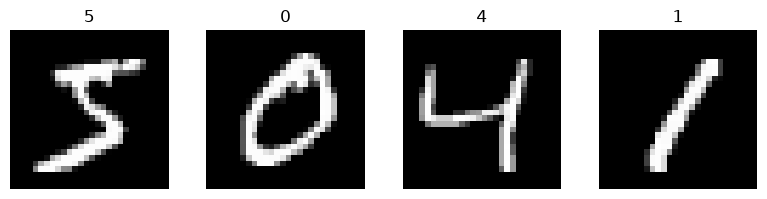

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(8, 2))
for i, ax in enumerate(axs):
    ax.imshow(x_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_train[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()

In [5]:
train_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=0.1, random_state=42, stratify=y_train
)
print('Training:', len(train_idx), 'Validation:', len(val_idx), 'Test:', len(y_test))

Training: 54000 Validation: 6000 Test: 10000


In [6]:
x_train = x_train.reshape((-1, 784))
x_test = x_test.reshape((-1, 784))
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

# Model

In [7]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(784, kernel_initializer='normal', activation='relu'),
    layers.Dense(10, kernel_initializer='normal', activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

# Training

Train for 100 epochs with batches of 200. Save the checkpoint with the lowest validation loss.

In [8]:
hist = model.fit(
    x_train[train_idx], y_train_cat[train_idx],
    validation_data=(x_train[val_idx], y_train_cat[val_idx]),
    epochs=100, batch_size=200, verbose=2,
    callbacks=[
        keras.callbacks.ModelCheckpoint('models/part2.keras', monitor='val_loss', save_best_only=True),
        keras.callbacks.CSVLogger('results/part2_history.csv')
    ]
)

Epoch 1/100
270/270 - 3s - 10ms/step - accuracy: 0.9169 - loss: 0.2929 - val_accuracy: 0.9553 - val_loss: 0.1617
Epoch 2/100
270/270 - 1s - 3ms/step - accuracy: 0.9656 - loss: 0.1196 - val_accuracy: 0.9670 - val_loss: 0.1205
Epoch 3/100
270/270 - 1s - 2ms/step - accuracy: 0.9783 - loss: 0.0768 - val_accuracy: 0.9722 - val_loss: 0.1017
Epoch 4/100
270/270 - 1s - 3ms/step - accuracy: 0.9856 - loss: 0.0532 - val_accuracy: 0.9750 - val_loss: 0.0905
Epoch 5/100
270/270 - 1s - 3ms/step - accuracy: 0.9904 - loss: 0.0377 - val_accuracy: 0.9750 - val_loss: 0.0865
Epoch 6/100
270/270 - 1s - 3ms/step - accuracy: 0.9939 - loss: 0.0270 - val_accuracy: 0.9763 - val_loss: 0.0836
Epoch 7/100
270/270 - 1s - 3ms/step - accuracy: 0.9960 - loss: 0.0196 - val_accuracy: 0.9782 - val_loss: 0.0796
Epoch 8/100
270/270 - 1s - 2ms/step - accuracy: 0.9978 - loss: 0.0144 - val_accuracy: 0.9798 - val_loss: 0.0776
Epoch 9/100
270/270 - 1s - 3ms/step - accuracy: 0.9984 - loss: 0.0108 - val_accuracy: 0.9783 - val_loss

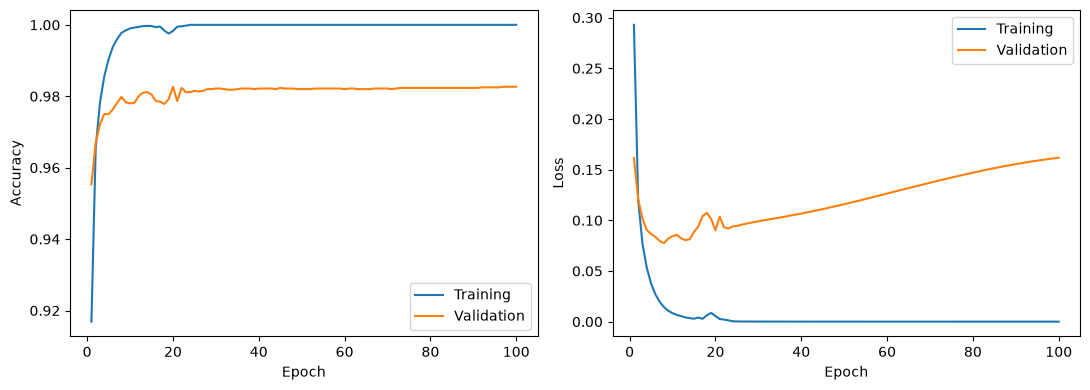

In [9]:
history = pd.DataFrame(hist.history)
epochs = np.arange(1, len(history) + 1)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axs, ['accuracy', 'loss']):
    ax.plot(epochs, history[metric], label='Training')
    if f'val_{metric}' in history:
        ax.plot(epochs, history[f'val_{metric}'], label='Validation')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric.capitalize())
    ax.legend()
plt.tight_layout()
plt.show()

# Results

In [12]:
loaded_model = keras.models.load_model('models/part2.keras')
loss, accuracy = loaded_model.evaluate(x_test, y_test_cat, verbose=0)
result = {
    'part': 'part2',
    'epochs': len(hist.epoch),
    'best_epoch': int(np.argmin(hist.history['val_loss']) + 1),
    'test_loss': loss,
    'test_accuracy': accuracy,
    'test_error': 1 - accuracy
}
display(pd.DataFrame([result]))

,part,epochs,best_epoch,test_loss,test_accuracy,test_error
0,part2,100,8,0.065142,0.9803,0.0197


# Test images

In [14]:
def predict_calc_acc(model, imgs, labels, names, name):
    probabilities = model.predict(imgs, verbose=0)
    predictions = probabilities.argmax(axis=1)
    table = pd.DataFrame({
        'image': names,
        'class': labels,
        'prediction': predictions,
        'confidence': probabilities.max(axis=1)
    })
    table['correct'] = table['class'] == table['prediction']
    print(f"Accuracy on {name}: {table['correct'].mean():.2%}")
    display(table)

    rows = int(np.ceil(len(imgs) / 5))
    fig, axs = plt.subplots(rows, 5, figsize=(12, 2.7 * rows), squeeze=False)
    for ax in axs.flat:
        ax.axis('off')
    for i, (img, ax) in enumerate(zip(imgs, axs.flat)):
        row = table.iloc[i]
        ax.imshow(img.reshape(28, 28), cmap='gray')
        ax.set_title(
            f"{row['class']} --> {row['prediction']}",
            fontsize=9,
            color='green' if row['correct'] else 'red'
        )
    plt.tight_layout()
    plt.show()

    return table

Accuracy on part2_test: 100.00%


,image,class,prediction,confidence,correct
0,3,0,0,0.999989,True
1,2,1,1,0.999719,True
2,1,2,2,0.999999,True
3,18,3,3,0.883746,True
4,4,4,4,0.999611,True
5,8,5,5,0.854677,True
6,11,6,6,0.999991,True
7,0,7,7,0.999979,True
8,61,8,8,0.995799,True
9,7,9,9,0.999851,True


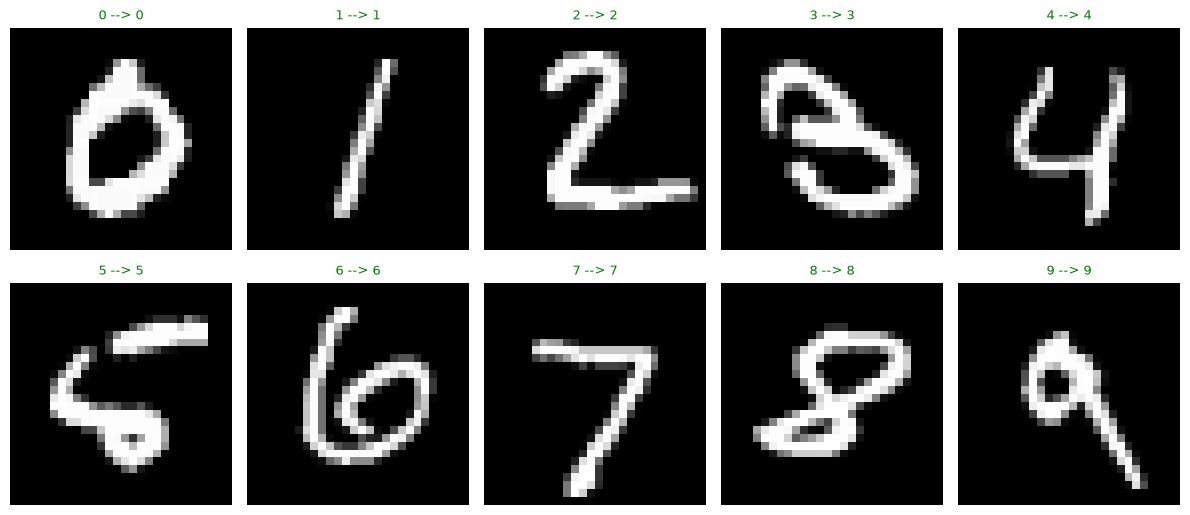

In [15]:
indices = np.array([np.flatnonzero(y_test == i)[0] for i in range(10)])
test_results = predict_calc_acc(loaded_model, x_test[indices], y_test[indices], indices, 'part2_test')

# New images

In [16]:
img_files = sorted(Path('images').glob('*.png'))
img_names = [fname.name for fname in img_files]
img_labels = np.array([int(fname.stem.split('_')[0]) for fname in img_files])

imgs = []
for fname in img_files:
    img = image.load_img(fname, color_mode='grayscale', target_size=(28, 28))
    imgs.append(image.img_to_array(img))
imgs = np.array(imgs)

Accuracy on part2_new: 80.00%


,image,class,prediction,confidence,correct
0,0_uci.png,0,0,0.999829,True
1,1_uci.png,1,1,0.770064,True
2,2_uci.png,2,2,0.999643,True
3,3_uci.png,3,3,1.000000,True
4,4_uci.png,4,4,0.985894,True
5,5_uci.png,5,3,0.959757,False
6,6_uci.png,6,6,0.998190,True
7,7_uci.png,7,8,0.935334,False
8,8_uci.png,8,8,0.999864,True
9,9_uci.png,9,9,0.828608,True


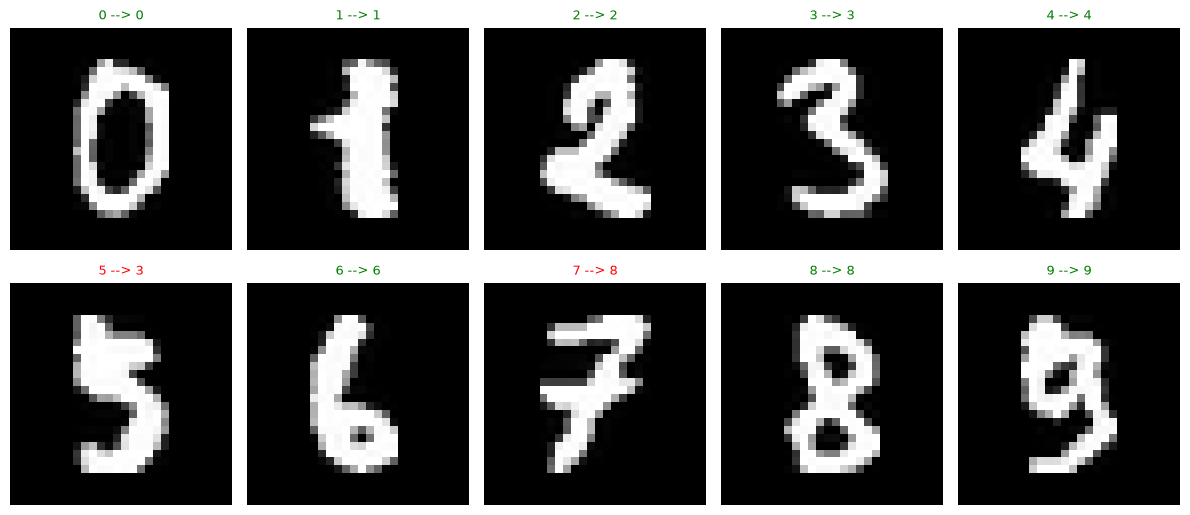

In [17]:
imgs = (255.0 - imgs) / 255.0
imgs = imgs.reshape((-1, 784))
new_results = predict_calc_acc(loaded_model, imgs, img_labels, img_names, 'part2_new')

# Summary

Перцептрон із 784 нейронами навчався **100 епох** із пакетом 200. Найменші валідаційні втрати отримано на епосі **8**. Збережена модель отримала **98.03%** на тестовій вибірці, помилка класифікації - 1.97%.

Мінімальні валідаційні втрати становили 0.0776, а після 100 епох - 0.1618. Навчальна точність наприкінці - 100.00%. Це ознаки перенавчання: подальше покращення на навчальних даних не покращує результат на валідації. Тому для розпізнавання завантажено найкращий checkpoint, а не останні ваги.

На десяти показаних тестових цифрах точність - 100%, на десяти зовнішніх цифрах UCI - **80%**. Помилки на зовнішніх зображеннях: `5_uci.png` --> `3`; `7_uci.png` --> `8`. Зовнішня вибірка мала і походить з іншого набору, тому її результат оцінюється окремо.